    Inlämningsuppgift - analys av Hälsostudie
    Kurs: Pythonprogrammering och statistisk dataanalys

### Förberedelse

- Läs in och granska datasetet
- Undersök vad som anses vara normalvärde för de hälsomarkörer som ingår i studien

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


data = pd.read_csv("data/health_study_dataset.csv")

In [17]:
# add a column for bmi, that is a better indicator of health risks than body weight alone
data["bmi"] = (data["weight"] / (data["height"] / 100) ** 2).round(2)
data = data[["id", "age", "sex", "weight", "height", "bmi", "systolic_bp", "cholesterol", "smoker", "disease"]]

In [18]:
display(data.sample(8))
display(data.info())
display(data.describe())
display(data.describe(include = ['str']))

,id,age,sex,weight,height,bmi,systolic_bp,cholesterol,smoker,disease
540,541,62,M,82.2,192.4,22.21,171.0,4.98,No,0
296,297,63,M,68.6,175.4,22.30,155.1,4.27,No,0
782,783,55,M,76.4,184.8,22.37,142.8,3.34,Yes,0
321,322,58,F,53.8,163.3,20.17,148.7,4.17,Yes,0
664,665,39,F,64.8,158.5,25.79,141.2,4.02,No,0
460,461,79,M,95.9,188.4,27.02,162.0,5.95,No,0
412,413,26,M,66.1,170.0,22.87,130.1,4.27,No,0
263,264,34,M,72.7,182.1,21.92,158.7,4.45,No,0


<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   weight       800 non-null    float64
 4   height       800 non-null    float64
 5   bmi          800 non-null    float64
 6   systolic_bp  800 non-null    float64
 7   cholesterol  800 non-null    float64
 8   smoker       800 non-null    str    
 9   disease      800 non-null    int64  
dtypes: float64(5), int64(3), str(2)
memory usage: 62.6 KB


None

,id,age,weight,height,bmi,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,73.413000,171.849250,24.933612,149.178625,4.929150,0.058750
std,231.0844,14.501118,13.685059,9.804259,4.661216,12.793360,0.848413,0.235303
min,1.0000,18.000000,33.700000,144.400000,12.630000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,64.800000,164.775000,21.917500,140.900000,4.327500,0.000000
50%,400.5000,50.000000,73.200000,171.350000,24.700000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,82.600000,178.925000,28.012500,157.600000,5.482500,0.000000
max,800.0000,90.000000,114.400000,200.400000,40.140000,185.900000,7.880000,1.000000


,sex,smoker
count,800,800
unique,2,2
top,F,No
freq,403,587


In [19]:
dup_rows = data.duplicated().sum()

if dup_rows > 0:
    data = data.drop_duplicates()
    print(f"{dup_rows} row(s) removed due to duplicates.")
else:
    print("There are no duplicate rows in the dataset.")

There are no duplicate rows in the dataset.


In [20]:
#print(data[['weight', 'sex', 'age', 'height']].sort_values(by='weight').head(20))

In [21]:
#print(data[['height', 'sex', 'age', 'weight']].sort_values(by='height').head(20))

In [22]:
reference_target_value = pd.DataFrame({
    "Mätvärde": [
        "--------------------",
        "Systoliskt blodtryck", "Systoliskt blodtryck", "Systoliskt blodtryck", "--------------------",
        "Totalkolesterol", "LDL-kolesterol",
        "HDL-kolesterol", "HDL-kolesterol", "--------------------",
        "BMI", "BMI", "BMI", "BMI"
    ],
    "Nivå": [
        "--------------",
        "Optimalt", "Normalt", "Förhöjt", "--------------",
        "Önskvärt", "Önskvärt",
        "Önskvärt (M)", "Önskvärt (K)", "--------------",
        "Undervikt", "Normalvikt", "Övervikt", "Obesitas"
    ],
    "Gränsvärde": [
        "-------------",
        "under 120", "120 – 140", "över 140", "-------------",
        "under 5,0", "under 3,0",
        "över 1,0", "över 1,2", "-------------",
        "under 18,5", "18,5 – 24,9", "25,0 – 29,9", "över 30,0"
    ],
    "Enhet": [
        "-------",
        "mmHg", "mmHg", "mmHg", "-------",
        "mmol/l", "mmol/l",
        "mmol/l", "mmol/l", "-------",
        "kg/m2", "kg/m2", "kg/m2", "kg/m2"
    ]
})

print("Referens- och riktvärden\n")
print(reference_target_value.to_string(index=False))
print("\nKälla: https://www.1177.se")

Referens- och riktvärden

            Mätvärde           Nivå    Gränsvärde   Enhet
-------------------- -------------- ------------- -------
Systoliskt blodtryck       Optimalt     under 120    mmHg
Systoliskt blodtryck        Normalt     120 – 140    mmHg
Systoliskt blodtryck        Förhöjt      över 140    mmHg
-------------------- -------------- ------------- -------
     Totalkolesterol       Önskvärt     under 5,0  mmol/l
      LDL-kolesterol       Önskvärt     under 3,0  mmol/l
      HDL-kolesterol   Önskvärt (M)      över 1,0  mmol/l
      HDL-kolesterol   Önskvärt (K)      över 1,2  mmol/l
-------------------- -------------- ------------- -------
                 BMI      Undervikt    under 18,5   kg/m2
                 BMI     Normalvikt   18,5 – 24,9   kg/m2
                 BMI       Övervikt   25,0 – 29,9   kg/m2
                 BMI       Obesitas     över 30,0   kg/m2

Källa: https://www.1177.se


#### _<span style="color:#2166ac">Observationer:</span>_

- Datasetet innehåller
    - 800 rader
    - 10 kolumner, varav en har lagts till
    - Inga saknade värden
    - Inga dubbletter  

- Datatyper
    - Numeriska: `id`, `age`, `height`, `weight`, `bmi`, `systolic_bp`, `cholesterol`, `disease`
    - Kategoriska: `sex`, `smoker`

- Variationsvidd och fördelning
    - Ålder varierar mellan 18 och 90 år
    - Fördelningen mellan kvinnor och män är jämn
    - En stor andel av deltagarna har förhöjt blodtryck
    - Andelen rökare i studien är ~ 25%
    - ≈ 6% har en odefinierad sjukdom  
  
  
    _Funderingar_:
    - _Är alla värdena för vikt och längd är korrekta? (Det finns deltagare med låg vikt som skicker ut lite)_
    - _Det framgår inte av datasetet vilken typ av kolesterol som avses_
        - _HDL, det "goda" kolesterolet_
        - _LDL, det "onda" kolesterolet_
        - _Total-kolesterol, HDL + LDL_  
        
        _Ett antagande är att det är Total-kolesterol som avses_
___

## Beskrivande analys
- Räkna ut medel, median, min och max för: age, weight, height, systolic_bp, cholesterol.
- Skapa minst __3 olika grafer__ (t.ex. histogram över blodtryck, boxplot över vikt per kön, stapeldiagram över andelen rökare).

In [23]:
columns_to_analyze = ["age", "weight", "height", "systolic_bp", "cholesterol"]
desc_stats = data[columns_to_analyze].agg(["mean", "median", "min", "max"]).round(2).T
desc_stats.columns = ["medel", "median", "minimum", "maximum"]

display(desc_stats)

,medel,median,minimum,maximum
age,49.43,50.00,18.0,90.00
weight,73.41,73.20,33.7,114.40
height,171.85,171.35,144.4,200.40
systolic_bp,149.18,149.40,106.8,185.90
cholesterol,4.93,4.97,2.5,7.88


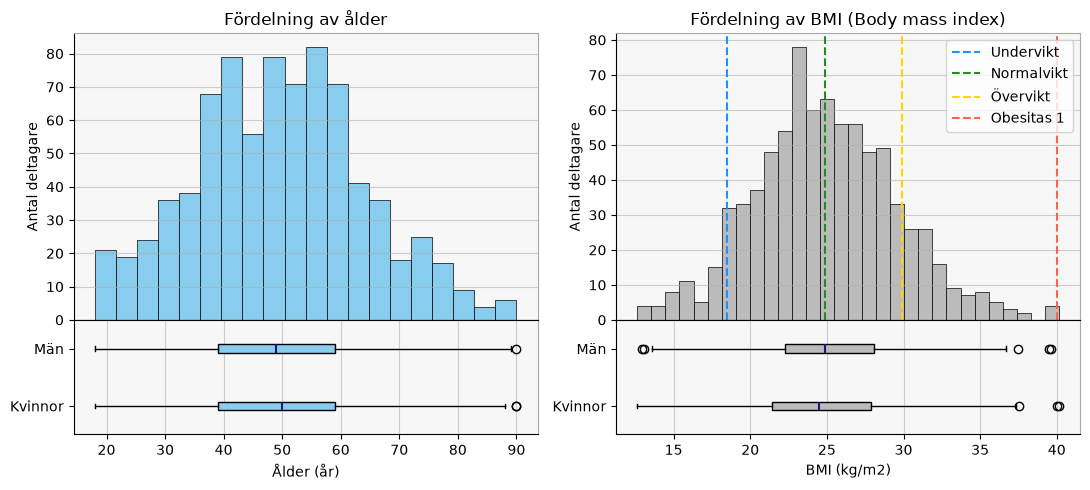

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), gridspec_kw={"height_ratios":[5,2], 'hspace': 0})

# age
axes[0,0].hist(data.age, bins=20, color='#88CCEE', edgecolor='black', linewidth=0.5)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title("Fördelning av ålder")
axes[0,0].set_xlabel("Ålder (år)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y", alpha=0.6)


axes[1,0].boxplot([data.loc[data.sex == "F", "age"], 
                data.loc[data.sex == "M", "age"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#88CCEE', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_xlabel("Ålder (år)")
axes[1,0].grid(True, axis="x", alpha=0.6)


# bmi
axes[0,1].hist(data.bmi, bins=30, color='#BBBBBB', edgecolor='black', linewidth=0.5)
axes[0,1].axvline(x=18.5, color='dodgerblue', linestyle='--', linewidth=1.5, label='Undervikt')
axes[0,1].axvline(x=24.9, color='forestgreen', linestyle='--', linewidth=1.5, label='Normalvikt')
axes[0,1].axvline(x=29.9, color='gold', linestyle='--', linewidth=1.5, label='Övervikt')
axes[0,1].axvline(x=40, color='tomato', linestyle='--', linewidth=1.5, label='Obesitas 1')
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title("Fördelning av BMI (Body mass index)")
axes[0,1].set_xlabel("BMI (kg/m2)")
axes[0,1].set_ylabel("Antal deltagare")
axes[0,1].grid(True, axis="y", alpha=0.6)
axes[0,1].legend()

axes[1,1].boxplot([data.loc[data.sex == "F", "bmi"], 
                data.loc[data.sex == "M", "bmi"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#BBBBBB', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_xlabel("BMI (kg/m2)")
axes[1,1].grid(True, axis="x", alpha=0.6)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

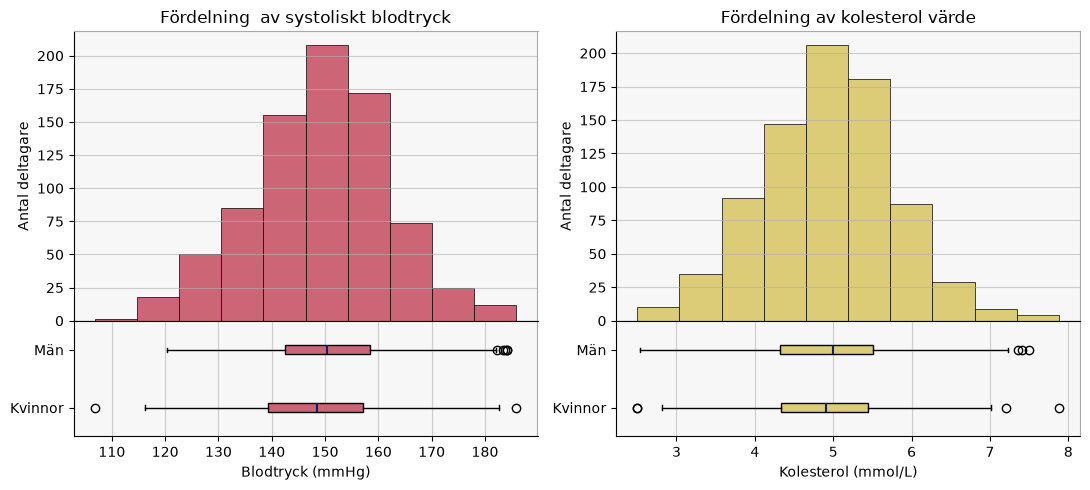

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 5), gridspec_kw={"height_ratios":[5,2], 'hspace': 0})

# systolic_bp
axes[0,0].hist(data.systolic_bp, bins=10, color='#CC6677', edgecolor='black', linewidth=0.5)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title("Fördelning  av systoliskt blodtryck")
axes[0,0].set_xlabel("Blodtryck (mmHg)")
axes[0,0].set_ylabel("Antal deltagare")
axes[0,0].grid(True, axis="y", alpha=0.6)

axes[1,0].boxplot([data.loc[data.sex == "F", "systolic_bp"], 
                data.loc[data.sex == "M", "systolic_bp"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#CC6677', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_xlabel("Blodtryck (mmHg)")
axes[1,0].grid(True, axis="x", alpha=0.6)


# cholesterol
axes[0,1].hist(data.cholesterol, bins=10, color='#DDCC77', edgecolor='black', linewidth=0.5)
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title("Fördelning av kolesterol värde")
axes[0,1].set_xlabel("Kolesterol (mmol/L)")
axes[0,1].set_ylabel("Antal deltagare")
axes[0,1].grid(True, axis="y", alpha=0.6)

axes[1,1].boxplot([data.loc[data.sex == "F", "cholesterol"], 
                data.loc[data.sex == "M", "cholesterol"]], 
                tick_labels=["Kvinnor", "Män"], 
                patch_artist=True,
                boxprops=dict(facecolor='#DDCC77', edgecolor='black'),
                medianprops = dict(color="midnightblue", linewidth=1.5),
                orientation='horizontal')
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_xlabel("Kolesterol (mmol/L)")
axes[1,1].grid(True, axis="x", alpha=0.6)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

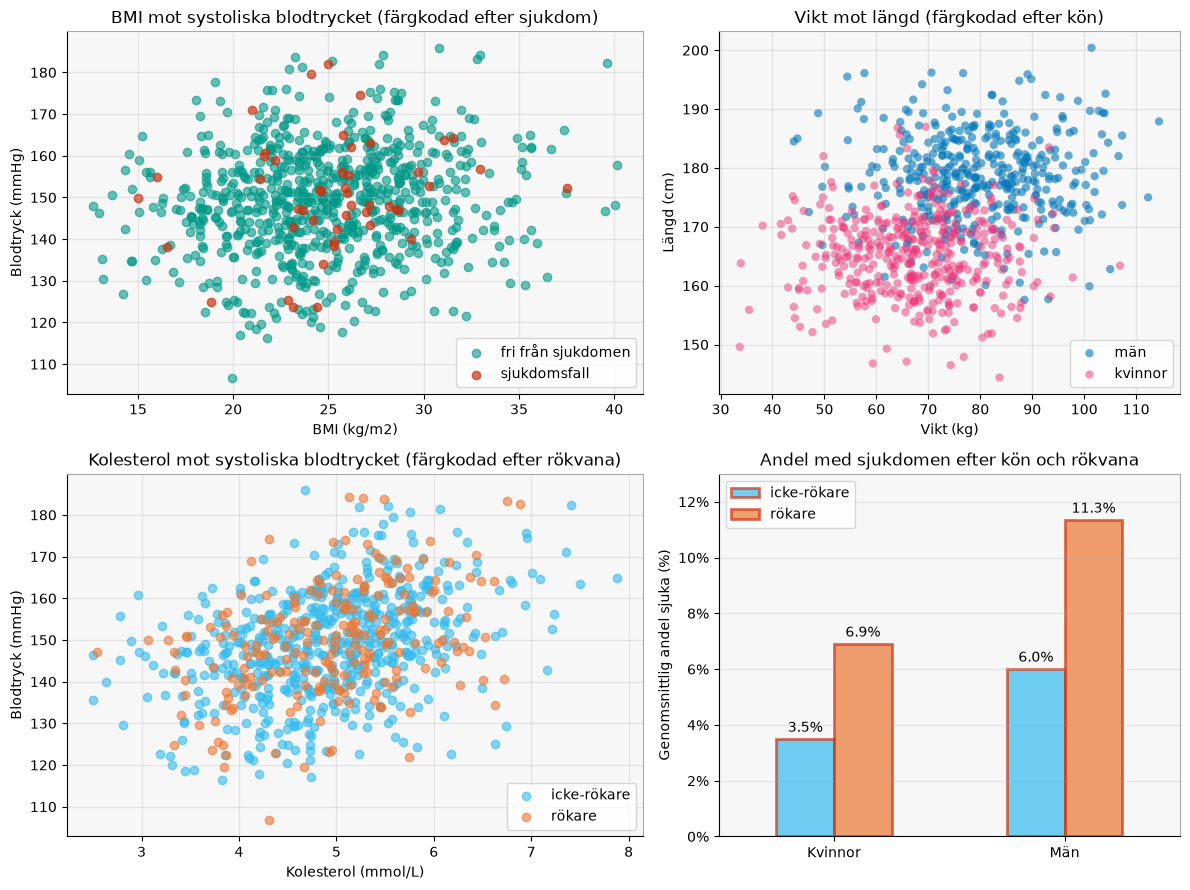

In [26]:
fig2, axes = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"width_ratios":[5,4]})

disease_n = data[data['disease'] == 0]
disease_y = data[data['disease'] == 1]

axes[0,0].scatter(disease_n['bmi'], disease_n['systolic_bp'], color='#009988', label='fri från sjukdomen', alpha=0.6)
axes[0,0].scatter(disease_y['bmi'], disease_y['systolic_bp'], color='#CC3311', label='sjukdomsfall', alpha=0.7)
axes[0,0].set_facecolor("#F7F7F7")
axes[0,0].set_title('BMI mot systoliska blodtrycket (färgkodad efter sjukdom)')
axes[0,0].set_xlabel('BMI (kg/m2)')
axes[0,0].set_ylabel('Blodtryck (mmHg)')
axes[0,0].legend(loc="lower right")
axes[0,0].grid(True, alpha=0.3)


m = data[data["sex"] == "M"]
f = data[data["sex"] == "F"]

axes[0,1].scatter(m['weight'], m['height'], color="#0077BB", label='män', alpha=0.6, edgecolors='none')
axes[0,1].scatter(f['weight'], f['height'], color="#EE3377", label='kvinnor', alpha=0.5, edgecolors='none')
axes[0,1].set_facecolor("#F7F7F7")
axes[0,1].set_title('Vikt mot längd (färgkodad efter kön)')
axes[0,1].set_xlabel('Vikt (kg)')
axes[0,1].set_ylabel('Längd (cm)')
axes[0,1].legend(loc="lower right")
axes[0,1].grid(True, alpha=0.3)


smoker_n = data[data["smoker"] == "No"]
smoker_y = data[data["smoker"] == "Yes"]

axes[1,0].scatter(smoker_n["cholesterol"], smoker_n["systolic_bp"], color="#33BBEE", label='icke-rökare', alpha=0.6)
axes[1,0].scatter(smoker_y["cholesterol"], smoker_y["systolic_bp"], color="#EE7733", label='rökare', alpha=0.6)
axes[1,0].set_facecolor("#F7F7F7")
axes[1,0].set_title('Kolesterol mot systoliska blodtrycket (färgkodad efter rökvana)')
axes[1,0].set_xlabel("Kolesterol (mmol/L)")
axes[1,0].set_ylabel("Blodtryck (mmHg)")
axes[1,0].legend(loc="lower right")
axes[1,0].grid(True, alpha=0.3)


import matplotlib.ticker as mtick
grouped = data.groupby(['sex', 'smoker'])['disease'].mean().unstack()*100
grouped = grouped.rename(index={'F': 'Kvinnor', 'M': 'Män'}, 
                         columns={'No': 'icke-rökare', 'Yes': 'rökare'})
grouped.plot(kind='bar', ax=axes[1, 1], color=['#33BBEE', '#EE7733'], alpha=0.7, edgecolor='#CC3311', linewidth=2)
axes[1,1].set_facecolor("#F7F7F7")
axes[1,1].set_ylim(top=13)
axes[1,1].set_title('Andel med sjukdomen efter kön och rökvana')
axes[1,1].set_xlabel('')
axes[1,1].set_ylabel('Genomsnittlig andel sjuka (%)')
axes[1,1].tick_params(axis='x', rotation=0)
axes[1,1].legend(title='')
axes[1,1].grid(True, axis="y", alpha=0.3)
axes[1,1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
for container in axes[1, 1].containers:
    axes[1,1].bar_label(container, fmt='%.1f%%', padding=3)


axes[0,0].spines['top'].set_color('darkgray')
axes[0,0].spines['right'].set_color('darkgray')
axes[1,0].spines['top'].set_color('darkgray')
axes[1,0].spines['right'].set_color('darkgray')
axes[0,1].spines['top'].set_color('darkgray')
axes[0,1].spines['right'].set_color('darkgray')
axes[1,1].spines['top'].set_color('darkgray')
axes[1,1].spines['right'].set_color('darkgray')

plt.tight_layout()

#### _<span style="color:#2166ac">Observationer:</span>_

- **Ålder:** Ungefär symmetrisk/klockformad fördelning kring 50 år, liknande spridning hos både män och kvinnor.

- **BMI:** Majoritetn av deltagarna har ett BMI som ligger inom normalvikt och övervikt, tämligen liknande spridning mellan män och kvinnor

- **Blodtryck:** Koncentrerat kring 145–155 mmHg med några enstaka extremvärden (outliers).

- **Kolesterol:** Koncentrerat kring 5 mmol/L med liknande medianer och spridning mellan män och kvinnor.


- **BMI mot blodtryck (efter sjukdom):** Det finns inget tydligt samband mellan högre BMI och högre blodtryck i denna studie. Sjukdomsfallen är utspridda över hela fältet, vilket tyder på att varken BMI eller blodtryck ensamt förklarar sjukdomen.

- **Vikt mot längd (efter kön):** Här syns en förväntad positiv korrelation: längre personer väger generellt mer. Diagrammet visar också en tydlig uppdelning mellan könen där män i genomsnitt är längre och tyngre än kvinnor.

- **Blodtryck mot kolesterol (efter rökvanor):** Det finns en svag positiv trend där högre kolesterolvärde tenderar att sammanfalla med ett något högre blodtryck. Rökare och icke-rökare är dock jämnt fördelade över skalan, vilket innebär att rökning inte verkar driva upp kolesterolet eller blodtrycket markant i just denna studie.

- **Sjukdomsfall uppdelat på rökvanor:** Andelen med sjukdomen är nästan dubbelt så hög bland rökare jämfört med icke-rökare och män har generellt en högre sjukdomsförekomst än kvinnor.
___

## Simulering kopplad till caset
- Beräkna andelen personer i datasetet som har sjukdomen.
- Använd numpy för att simulera 1000 slumpade personer med samma sannolikhet för sjukdom.
- Jämför den simulerade andelen med den verkliga andelen i datasetet.

In [27]:
actual_disease_rate = data["disease"].mean()

rng = np.random.default_rng(42)

simulated_outcome = rng.binomial(n=1, p=actual_disease_rate, size=1000)
simulated_disease_rate = simulated_outcome.mean()

print(f"Andel med sjukdomen (dataset):         {actual_disease_rate:.3%}")
print(f"Sannolikhet för sjukdom (simulering):  {simulated_disease_rate:.3%}")
print(f"Skillnad:                              {abs(actual_disease_rate - simulated_disease_rate)*100:.3}")

Andel med sjukdomen (dataset):         5.875%
Sannolikhet för sjukdom (simulering):  5.400%
Skillnad:                              0.475


#### _<span style="color:#2166ac">Resultat:</span>_

    Simuleringen med 1 000 utfall stämmer väl överens med datasetets verkliga sjukdomsfrekvens (5,875 %), med en liten slumpmässig avvikelse på 0,475 procentenheter.

Reproducerbarhet: Genom att använda np.random.default_rng(seed=42) säkerställer vi att simuleringarna ger exakt samma resultat vid varje körning.
___

## Konfidensintervall
- Beräkna ett konfidensintervall för medelvärdet av systolic_bp (t.ex. med normalapproximation eller bootstrap, som vi gått igenom på kursen).

_Beräkna konfidensintervallet med __två olika metoder__ (t.ex. normalapproximation och bootstrap) och jämför resultaten._

In [28]:
x = data["systolic_bp"]
mean = x.mean()

print(f"Medelvärde blodtryck: {mean:.2f} mmHg")


# 95% confidence interval with normal approximation
n = x.size
sd = x.std(ddof=1)
se = sd / np.sqrt(n) #standard error
z = 1.96
ci_norm = (mean - z * se, mean + z * se)

print(f"\n95% KI med normalapproximation: [{ci_norm[0]:.2f}, {ci_norm[1]:.2f}]")


# 95% confidence interval with bootstrap
rng = np.random.default_rng(42)
n_boot = 10000
bootstrap_means = []

for i in range(n_boot):
    sample = rng.choice(x, size=n, replace=True)
    bootstrap_means.append(sample.mean())

ci_boot = np.percentile(bootstrap_means, [2.5, 97.5])

print(f"\n95% KI med bootstrap ({n_boot} omsamplingar): [{ci_boot[0]:.2f}, {ci_boot[1]:.2f}]")

Medelvärde blodtryck: 149.18 mmHg

95% KI med normalapproximation: [148.29, 150.07]

95% KI med bootstrap (10000 omsamplingar): [148.31, 150.05]


#### _<span style="color:#2166ac">Jämförelse av metoder:</span>_

    Resultaten från de två metoderna ligger mycket nära varandra, vilket tyder på att medelvärdets samplingsfördelning är normalfördelad. Skillnaden mellan gränserna är bara hundradelar av en mmHg. Eftersom skillnaden på några hundradels mmHg saknar klinisk betydelse fungerar båda metoderna lika bra här, och normalapproximationen är fullt tillräcklig i detta fall.  

- Bootstrap är att föredra framför normalapproximation när data är kraftigt skevt fördelade, när stickprovet är litet eller när du ska skatta andra mått än medelvärdet.

- Normalapproximation bygger på centrala gränsvärdessatsen, som kräver antingen ett stort stickprov eller att grunddata redan är ungefär normalfördelade. När de villkoren inte är uppfyllda fångar bootstrap upp datamaterialets verkliga form bättre.
___

## Hypotesprövning
- Testa hypotesen: ”Rökare har högre medel-blodtryck än icke-rökare.”
- Använd en av metoderna vi gått igenom (t.ex. bootstrap eller enkel t-test-funktion).
- Förklara kort resultatet i en markdown-ruta.

_Gör en simulering för att undersöka __hur säkert ditt hypotes­test är__ (t.ex. hur ofta testet hittar en skillnad när den finns → power)._

In [29]:
# Welch's t-test
# --------------
# H0: mu_smoker <= mu_non_smoker
# H1: mu_smoker > mu_non_smoker
smoker_bp = data[data['smoker'] == 'Yes']['systolic_bp']
non_smoker_bp = data[data['smoker'] == 'No']['systolic_bp']

t_stat, p_val = stats.ttest_ind(smoker_bp, non_smoker_bp, equal_var=False, alternative='greater')

print(f"\nMedelblodtryck rökare: {smoker_bp.mean():.2f} mmHg")
print(f"Medelblodtryck icke-rökare: {non_smoker_bp.mean():.2f} mmHg")
print(f"\nWelch's t-test \nt-värde: {t_stat:.4f} \np-värde: {p_val:.4f}")


Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck icke-rökare: 149.05 mmHg

Welch's t-test 
t-värde: 0.4503 
p-värde: 0.3264


In [30]:
# Welch's t-test
# --------------
# H0: mu_smoker <= mu_non_smoker
# H1: mu_smoker > mu_non_smoker
smoker_bp = data[data['smoker'] == 'Yes']['systolic_bp']
non_smoker_bp = data[data['smoker'] == 'No']['systolic_bp']

t_stat, p_val = stats.ttest_ind(smoker_bp, non_smoker_bp, equal_var=False, alternative='greater')

print(f"\nMedelblodtryck rökare: {smoker_bp.mean():.2f} mmHg")
print(f"Medelblodtryck icke-rökare: {non_smoker_bp.mean():.2f} mmHg")
print(f"\nWelch's t-test \nt-värde: {t_stat:.4f} \np-värde: {p_val:.4f}")


# Power analysis
# --------------
n_smok = len(smoker_bp)
n_non_smok = len(non_smoker_bp)
mu_smok, std_smok = smoker_bp.mean(), smoker_bp.std()
mu_non_smok, std_non_smok = non_smoker_bp.mean(), non_smoker_bp.std()

# Simulation 1000 tests
rng = np.random.default_rng(42)
n_sim = 1000
significant_count = 0

for _ in range(n_sim):
    # create simulerad data
    sim_smok = rng.normal(loc=mu_smok, scale=std_smok, size=n_smok)
    sim_non_smok = rng.normal(loc=mu_non_smok, scale=std_non_smok, size=n_non_smok)
    # perform the test
    _, p = stats.ttest_ind(sim_smok, sim_non_smok, equal_var=False, alternative='greater')
    if p < 0.05:
        significant_count += 1

power = significant_count / n_sim
print(f"\nBeräknad statistisk styrka (Power): {power:.4f} ({power*100:.1f}%)")


Medelblodtryck rökare: 149.52 mmHg
Medelblodtryck icke-rökare: 149.05 mmHg

Welch's t-test 
t-värde: 0.4503 
p-värde: 0.3264

Beräknad statistisk styrka (Power): 0.1020 (10.2%)


#### _<span style="color:#2166ac">Resultat:</span>_

Vi använder Welch's t-test eftersom grupperna rökare och icke-rökare kan ha olika storlek och olika varians i blodtryck.   

Vi testar nollhypotesen (H₀) att rökare inte har högre blodtryck än icke-rökare mot alternativhypotesen (H₁) att rökare har högre medelblodtryck. 
    
**H₀ :** μ_rökare ≤ μ_icke-rökare  
**H₁ :** μ_rökare > μ_icke-rökare (ensidig test)
    
    Då p-värdet från t-testet är högre än signifikansnivån α = 0.05 kan vi inte förkastar nollhypotesen,  
    dvs, vi kan inte bekräfta hypotesen om att rökare har högre blodtryck utifrån detta dataset.

För att kontrollera detta gör vi en power analys på hypotesprövning, där vi simulerade 1000 experiment baserat på den observerade skillnaden mellan rökare och icke-rökare för att se hur ofta vårt t-test upptäcker skillnaden (p < 0.05). 

    Analyen visade att testets statistiska styrka (power) endast uppgick till 10,2%. Analyen visade att testets statistiska styrka (power) endast uppgick till 10,2%, vilket medför en hög risk för typ II-fel (att en faktisk skillnad inte upptäcks). Detta troligen på grund av för litet stickprov i förhållande till den lilla skillnaden och spridningen i datan.
    
    